# Thesis Fig. 5 — the per-mode error decomposition

Reproduction of Tepper (2026), Fig. 5 (thesis PDF p. 71; printed p. 64), panel by panel.

> A: where bias, variance, aliasing and network-floor terms dominate across modes. B: the bias–variance trade-off
> under observation noise. C: the network floor against N for smooth and polynomial spectra. D–F: the product
> structure of the bias, S(m) × λ²/(a_m + λ)², for matched, narrow and wide kernels.

**Panels:** A decomposition · B bias–variance · C network floor vs N · D target factor · E kernel factor · F error product.

**Acceptance (spec 6A.6):** per-mode errors match eq. 6.6 and 6.6′ within 5% (formula vs exact simulation).

**Parameters [D11]:** inferred from the figure (see `configs/thesis/fig5.yaml`): S(m) = e^{−m²/50}, N = 128, T = 32,
kernels compared at equal energy with λ = 10⁻³ a₀(matched). Panel F's printed sums give an independent check of
that inference.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seqnet.thesis as th
from seqnet.thesis.figures import load_config, save_data, load_data, save_figure, record_checks, style

style()
FIG = "fig5"
cfg = load_config(FIG)
N, T = cfg["N"], cfg["T"]
M_ext = 2 * N                                  # S extends past N/2 for the network floor
m_ext = np.arange(M_ext + 1)
S = np.exp(-m_ext**2 / cfg["S_width2"])
mh = np.arange(N // 2 + 1)
# equal-energy kernels (Thesis eq. 7.3), scaled so the matched kernel has a_0 = 1
raw = {k: th.Kernel.from_family("gaussian", N, sigma=s) for k, s in cfg["kernels"].items()}
K0 = raw["matched"].energy() / raw["matched"].alloc()[0]
kernels = {k: th.Kernel(values=v.values * np.sqrt(K0 / v.energy())) for k, v in raw.items()}
alloc = {k: v.alloc() for k, v in kernels.items()}
lam = cfg["lambda_rel"] * alloc["matched"][0]
{k: (a[0], a[16], a[30]) for k, a in alloc.items()}, lam

({'matched': (np.float64(1.0),
   np.float64(0.19429065878548932),
   np.float64(0.0031511115984495085)),
  'narrow': (np.float64(0.17637113823859368),
   np.float64(0.17540499735225398),
   np.float64(0.17340434437043545)),
  'wide': (np.float64(9.999995985290429),
   np.float64(4.138887392926548e-33),
   np.float64(6.020302766340996e-33))},
 np.float64(0.001))

## Panel A — per-mode error decomposition (matched kernel, T = 32, σ_η² = 0.01)

Per-mode bias λ²S/(a+λ)² and variance a²σ²/T/(a+λ)² (eq. 6.6′) for |m| ≤ T/2; aliasing S(m) for T/2 < |m| ≤ N/2
(eq. 6.8); network floor S(m) for |m| > N/2 (eq. 6.9). One-sided (m ≥ 0) per-mode values.

In [2]:
a = alloc[cfg["panelA_kernel"]]
s2 = cfg["noise_levels"][0]
a_ext = np.zeros(M_ext + 1); a_ext[: N // 2 + 1] = a
band = m_ext <= T / 2
bias = np.where(band, lam**2 * S / (a_ext + lam) ** 2, 0)
var = np.where(band, a_ext**2 * s2 / T / (a_ext + lam) ** 2, 0)
alias = np.where((m_ext > T / 2) & (m_ext <= N / 2), S, 0)
floor = np.where(m_ext > N / 2, S, 0)
save_data(FIG, "A_decomposition", params={"kernel": cfg["panelA_kernel"], "noise": s2, "T": T, "lambda": lam},
          m=m_ext, bias=bias, var=var, alias=alias, floor=floor)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig5/A_decomposition.npz')

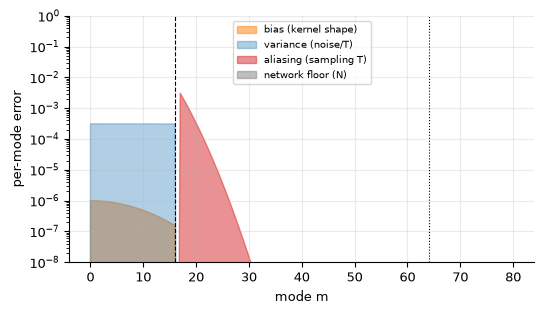

In [3]:
d = load_data(FIG, "A_decomposition")
fig, ax = plt.subplots(figsize=(6, 3.2))
mm = d["m"]; sl = mm <= 80
ax.fill_between(mm[sl], 1e-12, d["bias"][sl] + 1e-30, color="tab:orange", alpha=0.5, label="bias (kernel shape)")
ax.fill_between(mm[sl], 1e-12, d["var"][sl] + 1e-30, color="tab:blue", alpha=0.35, label="variance (noise/T)")
ax.fill_between(mm[sl], 1e-12, d["alias"][sl] + 1e-30, color="tab:red", alpha=0.5, label="aliasing (sampling T)")
ax.fill_between(mm[sl], 1e-12, d["floor"][sl] + 1e-30, color="0.5", alpha=0.5, label="network floor (N)")
ax.axvline(T / 2, ls="--", color="k", lw=0.8); ax.axvline(N / 2, ls=":", color="k", lw=0.8)
ax.set_yscale("log"); ax.set_ylim(1e-8, 1); ax.set_xlabel("mode m"); ax.set_ylabel("per-mode error"); ax.legend(fontsize=7)
save_figure(FIG, "A_decomposition", fig); plt.show()

## Panel B — bias–variance trade-off

Per-mode bias and variance (eq. 6.6′) for two noise levels; the marker is the first mode where the variance falls
below the bias.

In [4]:
mb = np.arange(N // 2 + 1)
bias_b = lam**2 * S[mb] / (a + lam) ** 2
vars_b = np.stack([a**2 * s2 / T / (a + lam) ** 2 for s2 in cfg["noise_levels"]])
cross = np.array([int(np.argmax(v < bias_b)) for v in vars_b])
save_data(FIG, "B_bias_variance", params={"noise_levels": cfg["noise_levels"]}, m=mb, bias=bias_b, var=vars_b, cross=cross)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig5/B_bias_variance.npz')

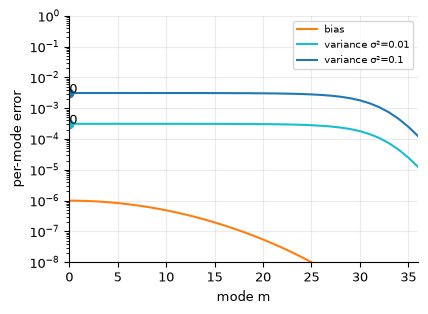

In [5]:
d = load_data(FIG, "B_bias_variance")
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.semilogy(d["m"], d["bias"], color="tab:orange", label="bias")
for v, s2, c, col in zip(d["var"], cfg["noise_levels"], d["cross"], ["tab:cyan", "tab:blue"]):
    ax.semilogy(d["m"], v, color=col, label=f"variance σ²={s2}"); ax.plot(c, v[c], "o", color=col); ax.annotate(str(c), (c, v[c]))
ax.set_ylim(1e-8, 1); ax.set_xlim(0, 36); ax.set_xlabel("mode m"); ax.set_ylabel("per-mode error"); ax.legend(fontsize=7)
save_figure(FIG, "B_bias_variance", fig); plt.show()

## Panel C — network floor against N

E_network = Σ_{|m|>N/2} S(m) (eq. 6.9) for the Gaussian PSD and a polynomial PSD with s = 1.5, with the closed-form
references (eq. I.13: erfc; eq. I.16: N^{−(2s−1)}). Both the two-sided sum (eq. 6.9 over signed modes) and the
one-sided sum the figure appears to plot are stored.

In [6]:
Ns = np.array(cfg["network_N"]); mm = np.arange(1, 20000)
Sg = np.exp(-mm**2 / cfg["S_width2"]); Sp = mm ** (-2 * cfg["poly_s"])
one_g = np.array([Sg[mm > n / 2].sum() for n in Ns]); one_p = np.array([Sp[mm > n / 2].sum() for n in Ns])
beta = 1 / cfg["S_width2"]
from scipy.special import erfc
ref_g = 0.5 * np.sqrt(np.pi / beta) * erfc(np.sqrt(beta) * Ns / 2)    # one-sided version of eq. I.13
ref_p = one_p[0] * (Ns / Ns[0]) ** (-(2 * cfg["poly_s"] - 1))
save_data(FIG, "C_network_floor", params={"poly_s": cfg["poly_s"]}, N=Ns, gauss_one=one_g, gauss_two=2 * one_g,
          poly_one=one_p, poly_two=2 * one_p, gauss_ref=ref_g, poly_ref=ref_p)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig5/C_network_floor.npz')

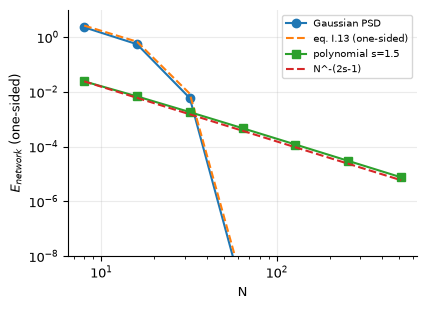

Gaussian one-sided: [2.3018 0.5552 0.0059]  polynomial one-sided: [0.0244 0.0069 0.0018]


In [7]:
d = load_data(FIG, "C_network_floor")
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.loglog(d["N"], d["gauss_one"], "o-", label="Gaussian PSD"); ax.loglog(d["N"], d["gauss_ref"], "--", label="eq. I.13 (one-sided)")
ax.loglog(d["N"], d["poly_one"], "s-", label=f"polynomial s={cfg['poly_s']}"); ax.loglog(d["N"], d["poly_ref"], "--", label="N^-(2s-1)")
ax.set_ylim(1e-8, 10); ax.set_xlabel("N"); ax.set_ylabel(r"$E_{network}$ (one-sided)"); ax.legend(fontsize=7)
save_figure(FIG, "C_network_floor", fig); plt.show()
print("Gaussian one-sided:", np.round(d["gauss_one"][:3], 4), " polynomial one-sided:", np.round(d["poly_one"][:3], 4))

## Panel D — target factor S(m)

In [8]:
save_data(FIG, "D_target_factor", m=mh, S=S[mh])

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig5/D_target_factor.npz')

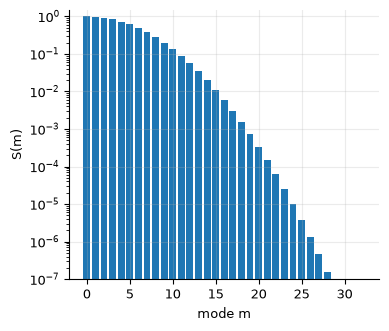

In [9]:
d = load_data(FIG, "D_target_factor")
fig, ax = plt.subplots(figsize=(4, 3.5))
ax.bar(d["m"][:33], d["S"][:33], color="tab:blue"); ax.set_yscale("log"); ax.set_ylim(1e-7, 1.5)
ax.set_xlabel("mode m"); ax.set_ylabel("S(m)")
save_figure(FIG, "D_target_factor", fig); plt.show()

## Panel E — kernel factor λ²/(a_m + λ)² for matched, narrow and wide kernels (equal energy)

In [10]:
names = list(cfg["kernels"])
kf = np.stack([lam**2 / (alloc[n] + lam) ** 2 for n in names])
save_data(FIG, "E_kernel_factor", params={"kernels": cfg["kernels"], "lambda": lam}, m=mh, factor=kf)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig5/E_kernel_factor.npz')

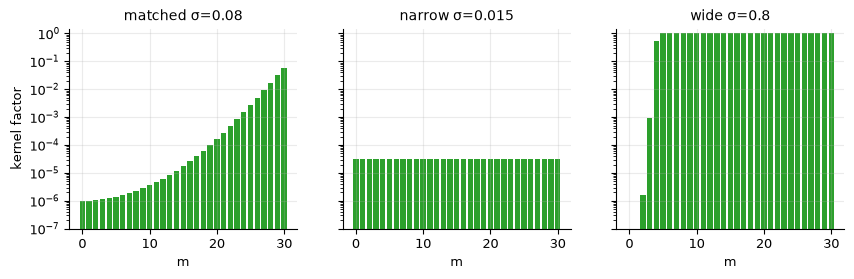

In [11]:
d = load_data(FIG, "E_kernel_factor")
fig, axs = plt.subplots(1, 3, figsize=(10, 2.6), sharey=True)
for ax, f, n in zip(axs, d["factor"], names):
    ax.bar(d["m"][:31], f[:31], color="tab:green"); ax.set_yscale("log"); ax.set_ylim(1e-7, 1.5)
    ax.set_title(f"{n} σ={cfg['kernels'][n]}"); ax.set_xlabel("m")
axs[0].set_ylabel("kernel factor")
save_figure(FIG, "E_kernel_factor", fig); plt.show()

## Panel F — error product E(m) = S(m) × kernel factor, with the sums Σ_m E(m)

Sums are reported one-sided (m ≥ 0) and two-sided (signed modes, eq. 6.7) against the printed values.

In [12]:
Em = kf * S[mh][None, :]
mult = th.mode_multiplicity(N)
sum_one = Em.sum(1); sum_two = (Em * mult).sum(1)
save_data(FIG, "F_error_product", m=mh, E=Em, S=S[mh], sum_one=sum_one, sum_two=sum_two,
          figure=np.array([cfg["figure_F_sums"][n] for n in names]))

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig5/F_error_product.npz')

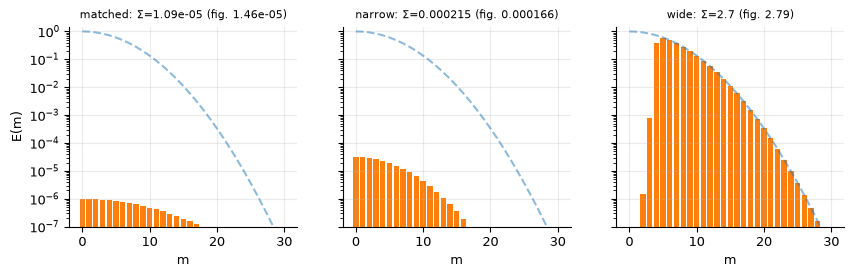

matched  one-sided 1.09e-05  two-sided 2.08e-05  figure 1.46e-05
narrow   one-sided 0.000215  two-sided 0.000399  figure 0.000166
wide     one-sided 2.7  two-sided 5.39  figure 2.79


In [13]:
d = load_data(FIG, "F_error_product")
fig, axs = plt.subplots(1, 3, figsize=(10, 2.6), sharey=True)
for ax, e, n, s1, f in zip(axs, d["E"], names, d["sum_one"], d["figure"]):
    ax.bar(d["m"][:31], e[:31], color="tab:orange"); ax.plot(d["m"][:31], d["S"][:31], "--", color="tab:blue", alpha=0.5)
    ax.set_yscale("log"); ax.set_ylim(1e-7, 1.5); ax.set_title(f"{n}: Σ={s1:.3g} (fig. {f:.3g})", fontsize=8); ax.set_xlabel("m")
axs[0].set_ylabel("E(m)")
save_figure(FIG, "F_error_product", fig); plt.show()
for n, s1, s2_, f in zip(names, d["sum_one"], d["sum_two"], d["figure"]): print(f"{n:8s} one-sided {s1:.3g}  two-sided {s2_:.3g}  figure {f:.3g}")

## Simulation check (acceptance)

Per-mode formula (eq. 6.6′) against the exact expected error of the ridge readout, at T_obs = N (the regime where the
thesis's decomposition is exact) for the three kernels and both noise levels, using a target band-limited below N/2.

In [14]:
S_bl = S[: N // 2].copy()   # band-limited below N/2
sched = th.Schedule(N, 1)
rows = []
for n in names:
    for s2 in [0.0] + list(cfg["noise_levels"]):
        exact = th.expected_error(kernels[n], S_bl, sched, lam, noise_var=s2)
        a_full = np.abs(kernels[n].spectrum()) ** 2
        Sf = np.concatenate([S_bl, np.zeros(N)])[np.abs(np.rint(np.fft.fftfreq(N, 1 / N)).astype(int))]
        formula = float(np.sum((lam**2 * Sf + a_full**2 * s2) / (a_full + lam) ** 2))
        thesis_66p = float(np.sum((lam**2 * Sf + a_full**2 * s2 / N) / (a_full + lam) ** 2))
        rows.append((n, s2, exact, formula, thesis_66p))
sim = np.array([[r[2], r[3], r[4]] for r in rows])
save_data(FIG, "G_simulation_check", exact=sim[:, 0], formula=sim[:, 1], thesis_1overT=sim[:, 2],
          labels=np.array([f"{r[0]}|{r[1]}" for r in rows]))
for r in rows: print(f"{r[0]:8s} s2={r[1]:<5} exact {r[2]:.4g}  eq.6.6' (no 1/T) {r[3]:.4g}  eq.6.6' as printed (1/T) {r[4]:.4g}")

matched  s2=0.0   exact 2.079e-05  eq.6.6' (no 1/T) 2.079e-05  eq.6.6' as printed (1/T) 2.079e-05
matched  s2=0.01  exact 0.6015  eq.6.6' (no 1/T) 0.6015  eq.6.6' as printed (1/T) 0.00472
matched  s2=0.1   exact 6.015  eq.6.6' (no 1/T) 6.015  eq.6.6' as printed (1/T) 0.04701
narrow   s2=0.0   exact 0.0003988  eq.6.6' (no 1/T) 0.0003988  eq.6.6' as printed (1/T) 0.0003988
narrow   s2=0.01  exact 1.266  eq.6.6' (no 1/T) 1.266  eq.6.6' as printed (1/T) 0.01028
narrow   s2=0.1   exact 12.65  eq.6.6' (no 1/T) 12.65  eq.6.6' as printed (1/T) 0.09925
wide     s2=0.0   exact 5.391  eq.6.6' (no 1/T) 5.391  eq.6.6' as printed (1/T) 5.391
wide     s2=0.01  exact 5.461  eq.6.6' (no 1/T) 5.461  eq.6.6' as printed (1/T) 5.392
wide     s2=0.1   exact 6.092  eq.6.6' (no 1/T) 6.092  eq.6.6' as printed (1/T) 5.397


## Acceptance

In [15]:
g = load_data(FIG, "G_simulation_check"); f = load_data(FIG, "F_error_product")
rel = np.abs(g["formula"] - g["exact"]) / g["exact"]
rel_printed = np.abs(g["thesis_1overT"] - g["exact"]) / g["exact"]
ratio = f["sum_one"] / f["figure"]
checks = [
    {"item": "eq. 6.6/6.6' match exact expected error (sum-of-squares convention)", "criterion": "< 5%",
     "value": float(rel.max()), "passed": bool(rel.max() < 0.05)},
    {"item": "eq. 6.6' with the printed 1/T noise factor", "criterion": "< 5% (reported)",
     "value": float(rel_printed.max()), "passed": bool(rel_printed.max() < 0.05)},
    {"item": "panel F sums vs printed values (checks the parameter inference)", "criterion": "ratio within [0.5, 2]",
     "value": ratio, "passed": bool(np.all((ratio > 0.5) & (ratio < 2)))},
]
record_checks(FIG, checks)
for c in checks: print(c)

{'item': "eq. 6.6/6.6' match exact expected error (sum-of-squares convention)", 'criterion': '< 5%', 'value': 8.758861318300695e-12, 'passed': True}
{'item': "eq. 6.6' with the printed 1/T noise factor", 'criterion': '< 5% (reported)', 'value': 0.9921840706542241, 'passed': False}
{'item': 'panel F sums vs printed values (checks the parameter inference)', 'criterion': 'ratio within [0.5, 2]', 'value': array([0.74618475, 1.29699941, 0.96613819]), 'passed': True}
